# Churn — visualisation des données

Ce notebook explore `data/final/all_tables.csv` : (34 000 contrats, 10 colonnes) avant la modélisation.
Question de départ : **qu'est-ce qui distingue les clients qui partent de ceux qui restent ?**

| Colonne | Type | Sens |
|---|---|---|
| `ANC_M` | nombre | ancienneté en mois |
| `HANDSET` | catégorie | techno du terminal (2G/3G/4G/5G) |
| `OFFRE` | catégorie | nom commercial de l'offre |
| `STATUT` | catégorie | état actuel (A actif / S suspendu) |
| `churn` | 0/1 | **le label** : 1 = part ou suspendu |
| `VOLUME_SESSION` | nombre | data moyenne par mois (Mo) |
| `MNT_RECH` | nombre | montant rechargé par mois (DT) |
| `MNT_FORFAIT` | nombre | montant en forfaits par mois (DT) |
| `APPEL_TOTAL` | nombre | **somme** des appels reçus + émis (min) |
| `SMS_TOTAL` | nombre | **somme** des SMS reçus + émis |

## 0. Préparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
df = pd.read_csv(ROOT / 'data' / 'final' / 'all_tables.csv', keep_default_na=False)

NUMERIQUES = ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT', 'APPEL_TOTAL', 'SMS_TOTAL']
for c in NUMERIQUES + ['churn']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

print('données chargées :', df.shape)

ModuleNotFoundError: No module named 'matplotlib'

## 1. Aperçu général

Avant tout graphique : combien de lignes, quels types, combien de valeurs manquantes.

In [ ]:
print(df.shape)
print()
print('valeurs manquantes par colonne :')
print(df.isna().sum())
print()
print('types :')
print(df.dtypes)

=== dimensions ===
34,000 lignes x 10 colonnes

=== valeurs manquantes ===
  VOLUME_SESSION    9,729  ( 28.6 %)
  MNT_RECH            217  (  0.6 %)
  MNT_FORFAIT      10,628  ( 31.3 %)

=== types ===
ANC_M               int64
HANDSET            object
OFFRE              object
STATUT             object
churn               int64
VOLUME_SESSION    float64
MNT_RECH          float64
MNT_FORFAIT       float64
APPEL_TOTAL       float64
SMS_TOTAL         float64


In [ ]:
df.head(10)

,ANC_M,HANDSET,OFFRE,STATUT,churn,VOLUME_SESSION,MNT_RECH,MNT_FORFAIT,APPEL_TOTAL,SMS_TOTAL
0,177,4G,PRE - TT 1500%,A,0,5277.095455,21.727273,14.281818,7359.43,1768.0
1,177,2G,PRE - Double,A,0,NaN,5.222222,0.800000,598.95,592.0
2,178,4G,PRE - TT 1500%,A,0,5242.772727,27.727273,1.737500,10223.95,2290.0
3,178,2G,PRE - Trankil TT,A,0,NaN,4.444444,NaN,758.47,687.0
4,178,2G,PRE - TT 1500%,A,0,NaN,13.636364,NaN,2479.33,837.0
5,197,4G,PRE - TT 1500%,A,0,1.275000,28.900000,NaN,9052.12,2268.0
6,177,4G,PRE - Trankil TT,A,0,366.516000,10.000000,12.000000,13440.40,1374.0
7,177,2G,PRE - TT 1500%,A,0,NaN,25.636364,0.000000,4664.93,1936.0
8,177,2G,PRE - Double,A,0,0.040000,8.272727,NaN,1032.38,781.0
9,177,5G,PRE - offre 40,A,0,384.399000,6.222222,5.400000,1447.85,1309.0


In [ ]:

df[NUMERIQUES].describe().round(2)

,ANC_M,VOLUME_SESSION,MNT_RECH,MNT_FORFAIT,APPEL_TOTAL,SMS_TOTAL
count,34000.0,24271.00,33783.00,23372.00,34000.00,34000.00
mean,91.8,5474.00,14.19,10.23,2699.65,1246.11
std,91.7,10720.20,21.30,17.12,3929.84,1223.03
min,3.0,0.00,0.88,0.00,0.00,0.00
25%,16.0,205.47,4.91,1.85,358.37,567.00
50%,57.0,1171.74,8.33,4.98,1298.49,1010.00
75%,133.0,5306.50,17.55,13.00,3444.59,1640.00
max,311.0,194047.23,2451.50,1223.00,67259.25,49391.00


## 2. Le label : distribution du churn

Question centrale : **les classes sont-elles équilibrées ?**


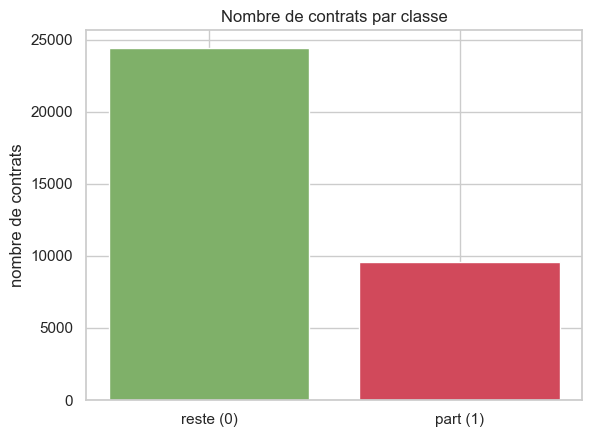

churn
0    24440
1     9560
Name: count, dtype: int64

churn
0    71.9
1    28.1
Name: count, dtype: float64


In [3]:
compte = df['churn'].value_counts().sort_index()

plt.bar(['reste (0)', 'part (1)'], compte.values, color=['#7fb069', '#d1495b'])
plt.ylabel('nombre de contrats')
plt.title('Nombre de contrats par classe')
plt.show()

print(compte)
print()
print((compte / len(df) * 100).round(1))

## 3. Distribution des variables numériques

Distribution des variables numériques
On regarde la forme de chaque variable avec un histogramme.

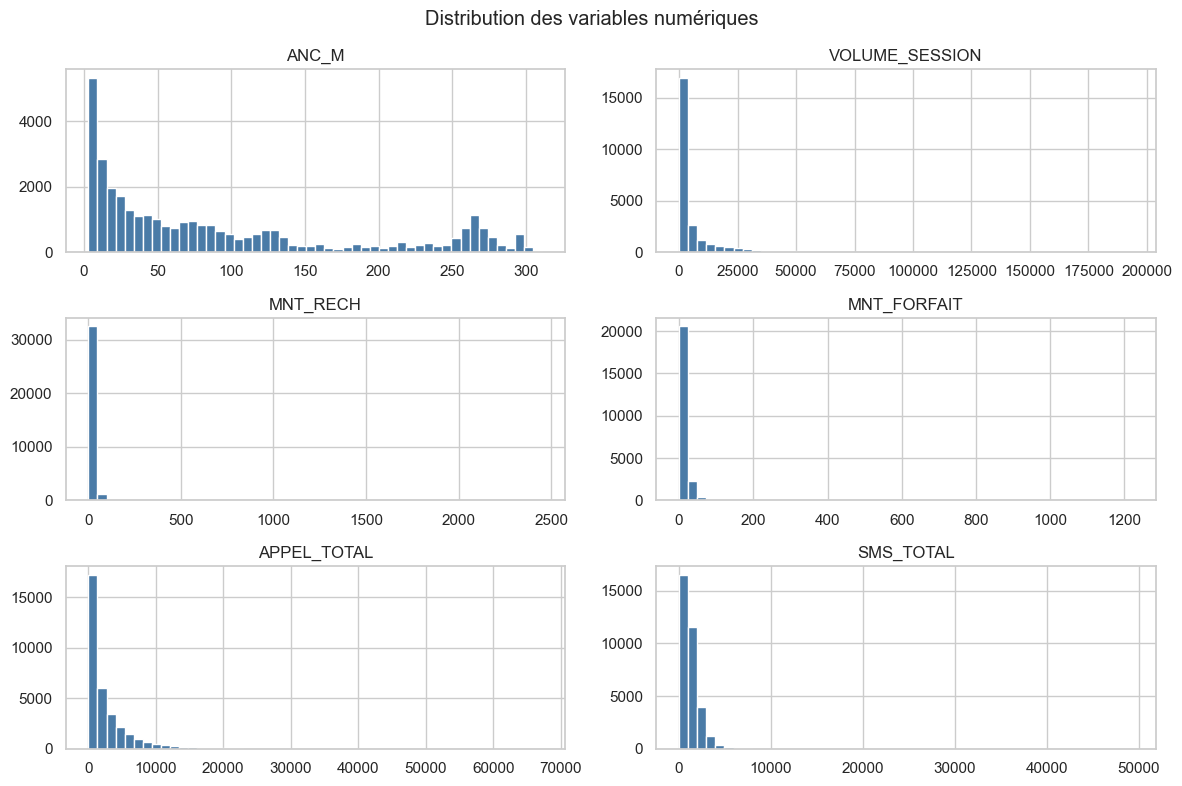

In [4]:
df[NUMERIQUES].hist(bins=50, figsize=(12, 8), color='#4a7ba7')
plt.suptitle('Distribution des variables numériques')
plt.tight_layout()
plt.show()

## 4. Les valeurs numériques par classe de churn
Est-ce que les clients qui partent ont un profil différent ?
Sur un boxplot, si les deux boîtes sont décalées, la variable est informative.

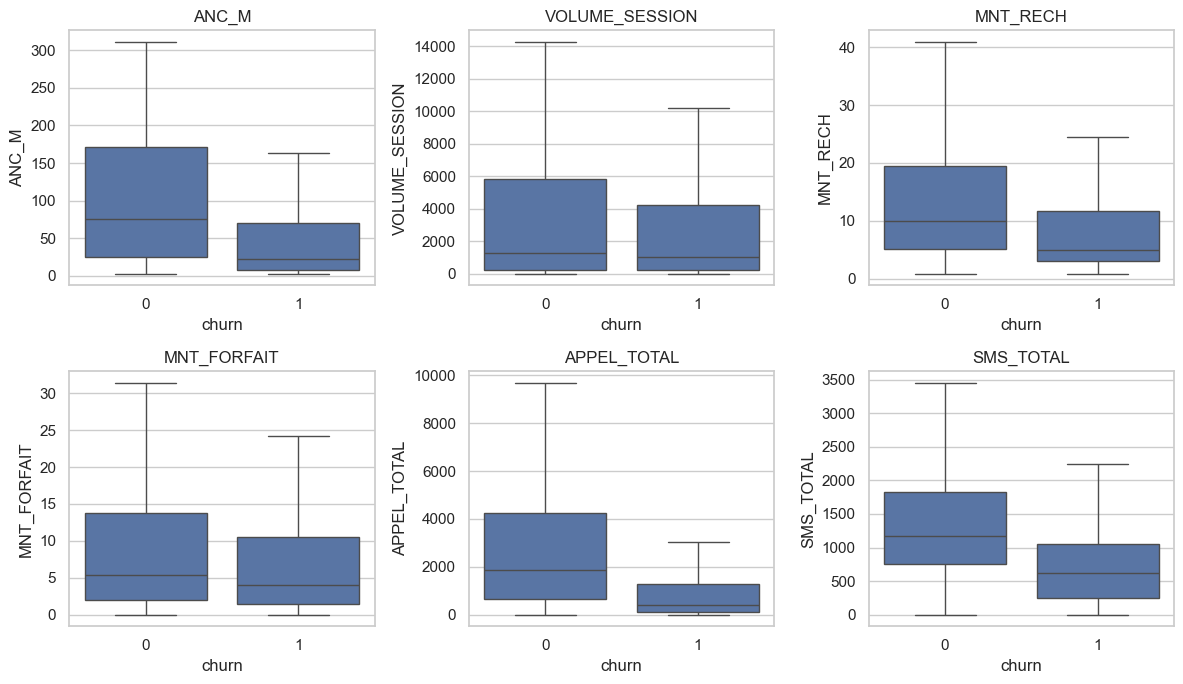

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flatten(), NUMERIQUES):
    sns.boxplot(data=df, x='churn', y=col, ax=ax, showfliers=False)  # sans les points extrêmes
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
# médiane de chaque variable pour chaque classe
mediane = df.groupby('churn')[NUMERIQUES].median().T
mediane.columns = ['reste (0)', 'part (1)']
mediane['écart %'] = ((mediane['part (1)'] / mediane['reste (0)'] - 1) * 100).round(1)
mediane.round(2)

,reste (0),part (1),écart %
ANC_M,75.00,23.00,-69.3
VOLUME_SESSION,1260.05,1009.60,-19.9
MNT_RECH,10.00,5.00,-50.0
MNT_FORFAIT,5.33,4.00,-25.0
APPEL_TOTAL,1854.64,400.06,-78.4
SMS_TOTAL,1178.00,615.00,-47.8


## 5. Variables catégorielles et churn

Pour chaque catégorie, on calcule le **taux de churn** (part de clients qui partent).

In [ ]:
# Pour chaque variable catégorielle, on calcule le taux de churn de chaque catégorie
for col in ['HANDSET', 'STATUT']:
    t = df.groupby(col)['churn'].agg(contrats='size', taux_churn='mean')
    t['taux_churn'] = (t['taux_churn'] * 100).round(1)
    print(f'=== {col} ===')
    print(t.sort_values('taux_churn', ascending=False))
    print()

=== HANDSET ===
         contrats  taux_churn
HANDSET                      
NA           1302        57.0
3G           1083        29.7
4G          19929        28.8
2G          10253        23.8
5G           1433        21.6

=== STATUT ===
        contrats  taux_churn
STATUT                      
S           8534        82.9
A          25466         9.8



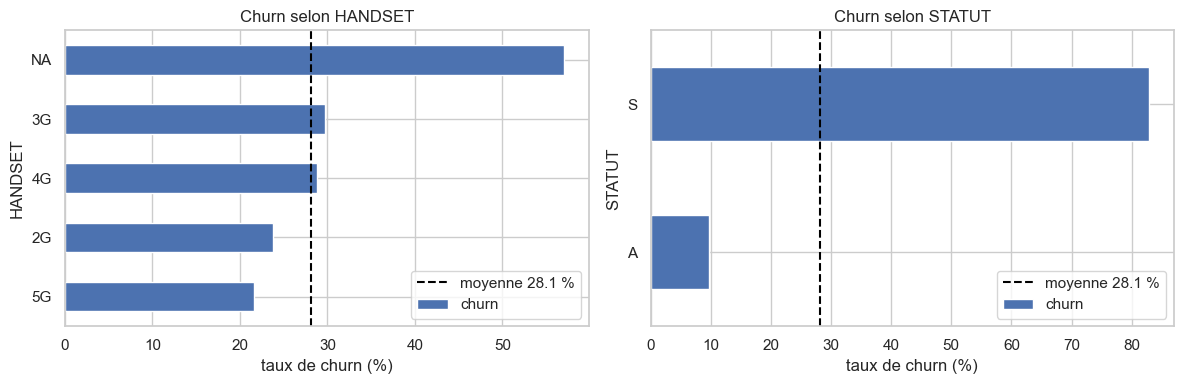

In [ ]:
# Taux de churn moyen de tous les clients, en % (sert de repère sur les graphiques)
moyenne = df['churn'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['HANDSET', 'STATUT']):
    (df.groupby(col)['churn'].mean() * 100).sort_values().plot(kind='barh', ax=ax)
    ax.axvline(moyenne, color='black', linestyle='--', label=f'moyenne {moyenne:.1f} %')
    ax.set_xlabel('taux de churn (%)')
    ax.set_title(f'Churn selon {col}')
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Corrélations entre variables

La corrélation va de -1 à +1. Proche de 0 : pas de lien linéaire.
On la regarde pour deux raisons : le lien de chaque variable avec `churn`, et les variables qui se ressemblent entre elles.

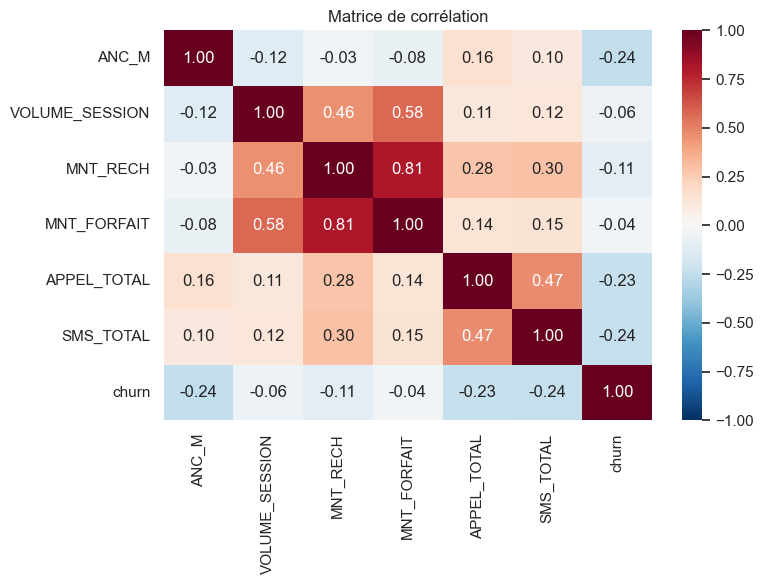

corrélation avec le churn :
ANC_M            -0.243
SMS_TOTAL        -0.236
APPEL_TOTAL      -0.228
MNT_RECH         -0.105
VOLUME_SESSION   -0.059
MNT_FORFAIT      -0.038
Name: churn, dtype: float64


In [11]:
corr = df[NUMERIQUES + ['churn']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

print('corrélation avec le churn :')
print(corr['churn'].drop('churn').sort_values().round(3))

## 7. L'ancienneté

On regroupe `ANC_M` en tranches pour voir comment le churn évolue avec l'ancienneté.

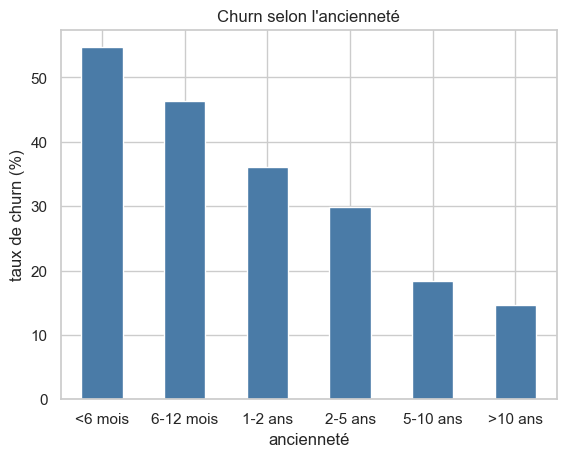

             contrats  taux_churn
tranche_anc                      
<6 mois          3605        54.7
6-12 mois        3171        46.3
1-2 ans          4274        36.1
2-5 ans          6387        29.9
5-10 ans         6640        18.4
>10 ans          9923        14.6


In [12]:
df['tranche_anc'] = pd.cut(df['ANC_M'],
                           bins=[0, 6, 12, 24, 60, 120, 1000],
                           labels=['<6 mois', '6-12 mois', '1-2 ans', '2-5 ans', '5-10 ans', '>10 ans'])

t = df.groupby('tranche_anc', observed=False)['churn'].agg(contrats='size', taux_churn='mean')
t['taux_churn'] = (t['taux_churn'] * 100).round(1)

t['taux_churn'].plot(kind='bar', color='#4a7ba7')
plt.ylabel('taux de churn (%)')
plt.xlabel('ancienneté')
plt.title('Churn selon l\'ancienneté')
plt.xticks(rotation=0)
plt.show()

print(t)

## 8. Ce qu'on retient

1. **Classes déséquilibrées** : 71,9 % de clients qui restent, 28,1 % qui partent. Un modèle qui répondrait toujours « reste » aurait 72 % de bonnes réponses sans rien apprendre, donc l'accuracy seule serait trompeuse.
2. **Valeurs extrêmes** : les variables numériques sont très étalées (ex. `VOLUME_SESSION` : médiane 1 172, maximum 194 047).
3. **Valeurs manquantes** : `VOLUME_SESSION` 28,6 %, `MNT_FORFAIT` 31,3 %, `MNT_RECH` 0,6 %. La cause reste à vérifier.
4. **`STATUT` est la variable la plus liée au churn** : 82,9 % de churn pour les clients suspendus (S) contre 9,8 % pour les actifs (A). Les clients avec `HANDSET` = NA ont aussi un churn élevé (57,0 %).
5. **Ancienneté** : le churn baisse régulièrement quand l'ancienneté augmente (54,7 % avant 6 mois, 14,6 % après 10 ans).
6. **Profil des partants** : leurs médianes sont plus basses sur toutes les variables numériques, surtout `APPEL_TOTAL` (-78,5 %) et `ANC_M` (-69,3 %).
7. **Variables liées entre elles** : `MNT_RECH` et `MNT_FORFAIT` sont fortement corrélées (r = 0,81).